In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, os
# Make the project root (which holds evqaoa/ and experiments/) importable.
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project root:', ROOT)

project root: /Users/sakxamshrestha/Desktop/IQ-hackathon/ev-qaoa-iq


# 01 - Penalty weights vs. constraint-preserving mixers

**Motivation.** In the starting prototype every vehicle must charge in exactly `need` slots.
A plain QAOA (X mixer, Hadamard start) explores all 2^12 = 4096 bitstrings, but only 216 of them
are valid schedules (5.3 %). Two ways to cope:

1. **Penalty term** - add `penalty * (slots charged - slots needed)^2` to the cost and hope the optimiser stays on valid schedules. How big should the penalty be?
2. **Constraint-preserving XY mixer** - start in a valid state (Dicke or simple basis state) and only ever swap 1s and 0s inside one vehicle's slots, so invalid schedules are never reached.

**Workflow.**
1. Build the 3-vehicle x 4-slot problem and brute-force the best/worst valid schedule.
2. For each configuration and QAOA depth p = 1, 2, 3, optimise the angles with COBYLA (warm-started from p-1) using exact statevector probabilities (no shot noise).
3. **Score every configuration on the same penalty-free objective**, counting only the valid-schedule part of the distribution: *feasible rate* (probability of a valid schedule), *P(optimal)* (probability of the best schedule) and *approximation ratio* (0 = average of the worst schedule, 1 = best schedule, measured on the valid part).
4. Repeat for 3 random seeds and report mean and spread.

Note: the X-mixer circuits are *optimised* with the penalty included, but *scored* without it.

In [3]:
import json, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from evqaoa import EXAMPLE_3x4, objective_scales
from experiments.mixer_penalty import (make_problem, random_baseline, run_sweep,
                                       summarise, build_configs)

INST = EXAMPLE_3x4
LAM = (0.5, 0.3, 0.2)            # weights on (cost, peak, wear), as upstream
PENALTIES = (0, 0.25, 0.5, 1, 2, 5, 10)
SEEDS = (0, 1, 2)
P_MAX, RESTARTS, MAXITER = 3, 3, 300
OUT = os.path.join(ROOT, 'results', '01_mixer_penalty')
os.makedirs(OUT, exist_ok=True)

problem = make_problem(INST, LAM, objective_scales(INST))
baseline = random_baseline(INST)
print('objective scales:', problem['scale'])
print('best / worst valid energy:', round(problem['E_best'], 4), round(problem['E_worst'], 4))
print('random-guess feasible rate:', round(baseline, 4))

objective scales: (21.0, 18.0, 9.0)
best / worst valid energy: 0.5175 0.9333
random-guess feasible rate: 0.0527


## Run the ablation
About 9 configurations x 3 depths x 3 seeds of COBYLA optimisation on 12 qubits.

In [4]:
t0 = time.time()
rows = run_sweep(INST, problem, PENALTIES, P_MAX, RESTARTS, MAXITER, SEEDS)
runtime = time.time() - t0
print(f'{len(rows)} optimisation runs in {runtime:.0f} s')

81 optimisation runs in 420 s


In [5]:
fs = summarise(rows, 'feasible_rate')
po = summarise(rows, 'p_optimal')
ar = summarise(rows, 'approx_ratio')
names = [c['name'] for c in build_configs(PENALTIES)]
print(f"{'config':<12} p  feasible   P(opt)   approx-ratio   (mean over {len(SEEDS)} seeds)")
for n in names:
    for p in range(1, P_MAX + 1):
        print(f"{n:<12} {p}  {fs[(n,p)][0]:8.3f}  {po[(n,p)][0]:7.4f}  {ar[(n,p)][0]:9.3f}")

with open(os.path.join(OUT, 'results.json'), 'w') as f:
    json.dump(dict(lam=LAM, penalties=PENALTIES, seeds=SEEDS, maxiter=MAXITER,
                   restarts=RESTARTS, random_feasible_rate=baseline,
                   E_best=problem['E_best'], E_worst=problem['E_worst'],
                   runtime_s=runtime, rows=rows), f, indent=1)

config       p  feasible   P(opt)   approx-ratio   (mean over 3 seeds)
X+H pen=0    1     0.000   0.0000      0.748
X+H pen=0    2     0.000   0.0000      0.757
X+H pen=0    3     0.000   0.0000      0.739
X+H pen=0.25 1     0.342   0.0113      0.683
X+H pen=0.25 2     0.431   0.0156      0.693
X+H pen=0.25 3     0.492   0.0201      0.708
X+H pen=0.5  1     0.388   0.0117      0.676
X+H pen=0.5  2     0.389   0.0117      0.676
X+H pen=0.5  3     0.881   0.0261      0.674
X+H pen=1    1     0.400   0.0114      0.671
X+H pen=1    2     0.693   0.0171      0.663
X+H pen=1    3     0.832   0.0213      0.672
X+H pen=2    1     0.390   0.0116      0.676
X+H pen=2    2     0.866   0.0259      0.676
X+H pen=2    3     0.951   0.0282      0.676
X+H pen=5    1     0.389   0.0118      0.676
X+H pen=5    2     0.756   0.0209      0.668
X+H pen=5    3     0.895   0.0250      0.663
X+H pen=10   1     0.399   0.0113      0.672
X+H pen=10   2     0.799   0.0218      0.674
X+H pen=10   3     0.935   0.

## Plot 1 - Penalty sweep (X mixer + Hadamard start)
Each curve is one depth p; error bars are the standard deviation over seeds. The dotted line is the random-guess feasible rate.

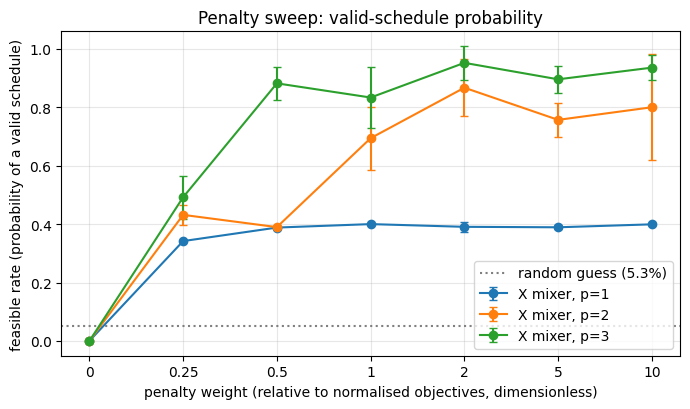

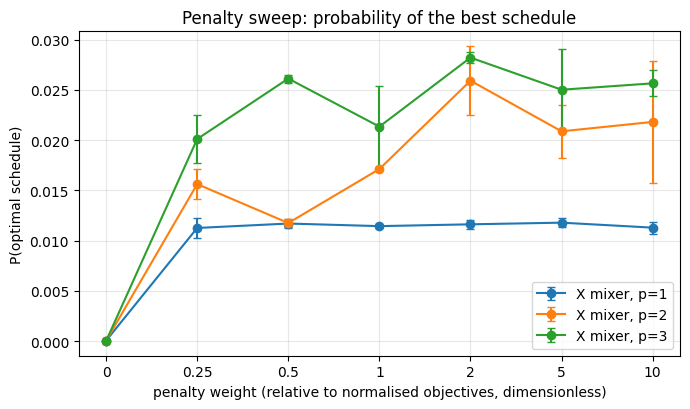

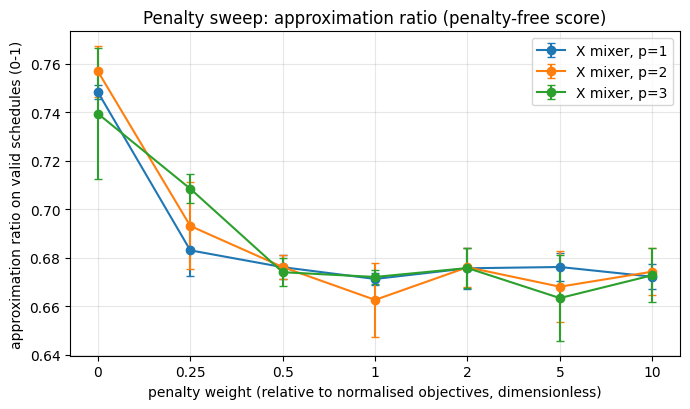

In [6]:
def sweep_plot(metric, summary, ylabel, title, fname, baseline_line=None):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    xs = np.arange(len(PENALTIES))
    for p in range(1, P_MAX + 1):
        m = [summary[(f'X+H pen={pen:g}', p)][0] for pen in PENALTIES]
        s = [summary[(f'X+H pen={pen:g}', p)][1] for pen in PENALTIES]
        ax.errorbar(xs, m, yerr=s, marker='o', capsize=3, label=f'X mixer, p={p}')
    if baseline_line is not None:
        ax.axhline(baseline_line, ls=':', color='gray', label=f'random guess ({baseline_line:.1%})')
    ax.set_xticks(xs); ax.set_xticklabels([f'{q:g}' for q in PENALTIES])
    ax.set_xlabel('penalty weight (relative to normalised objectives, dimensionless)')
    ax.set_ylabel(ylabel); ax.set_title(title); ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout(); fig.savefig(os.path.join(OUT, fname), dpi=150); plt.show()

sweep_plot('feasible_rate', fs, 'feasible rate (probability of a valid schedule)',
           'Penalty sweep: valid-schedule probability', 'penalty_feasible_rate.png', baseline)
sweep_plot('p_optimal', po, 'P(optimal schedule)',
           'Penalty sweep: probability of the best schedule', 'penalty_p_optimal.png')
sweep_plot('approx_ratio', ar, 'approximation ratio on valid schedules (0-1)',
           'Penalty sweep: approximation ratio (penalty-free score)', 'penalty_approx_ratio.png')

## Plot 2 - Mixer comparison vs. depth p
Best X-mixer penalty (highest mean feasible rate at p=3) against the two XY variants.

best penalty at p=3 by feasible rate: 2


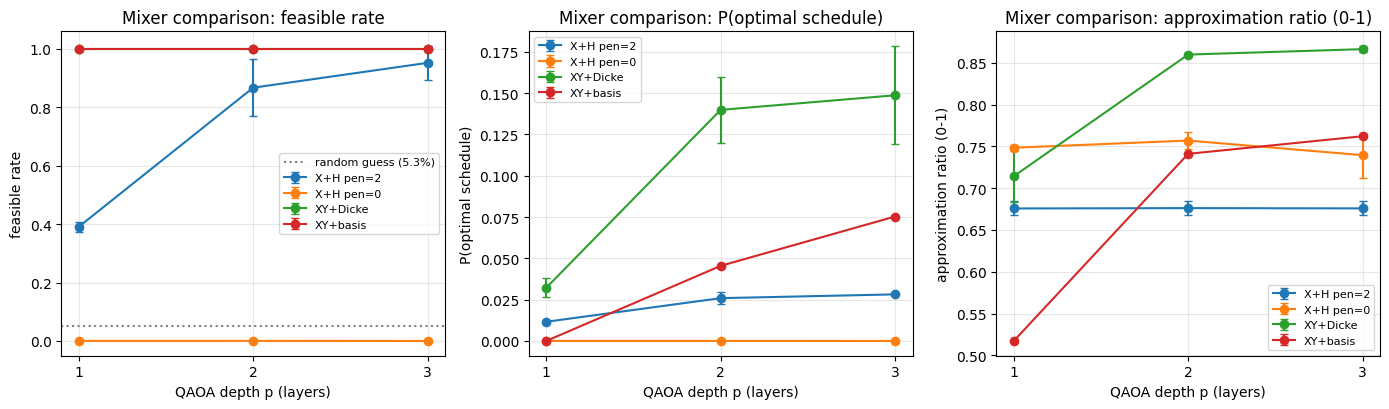

In [7]:
best_pen = max(PENALTIES, key=lambda q: fs[(f'X+H pen={q:g}', P_MAX)][0])
print('best penalty at p=%d by feasible rate: %g' % (P_MAX, best_pen))
chosen = [f'X+H pen={best_pen:g}', 'X+H pen=0', 'XY+Dicke', 'XY+basis']
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
specs = [(fs, 'feasible rate'), (po, 'P(optimal schedule)'), (ar, 'approximation ratio (0-1)')]
for ax, (summ, label) in zip(axes, specs):
    for n in chosen:
        ps = range(1, P_MAX + 1)
        ax.errorbar(list(ps), [summ[(n, p)][0] for p in ps], yerr=[summ[(n, p)][1] for p in ps],
                    marker='o', capsize=3, label=n)
    if label == 'feasible rate':
        ax.axhline(baseline, ls=':', color='gray', label=f'random guess ({baseline:.1%})')
    ax.set_xticks(list(range(1, P_MAX + 1)))
    ax.set_xlabel('QAOA depth p (layers)'); ax.set_ylabel(label)
    ax.set_title(f'Mixer comparison: {label}'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT, 'mixer_comparison.png'), dpi=150); plt.show()

## Plot 3 - What improved? Feasible rate and optimal-schedule probability at p=3
Bars show the mean over seeds; the dotted line is the random-guess feasible rate.

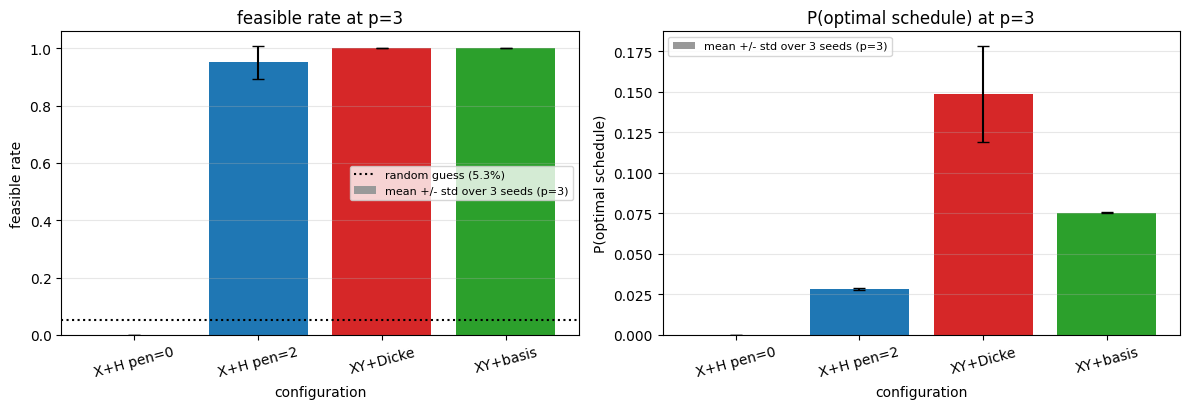

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
labels = ['X+H pen=0', f'X+H pen={best_pen:g}', 'XY+Dicke', 'XY+basis']
for ax, (summ, label) in zip(axes, [(fs, 'feasible rate'), (po, 'P(optimal schedule)')]):
    m = [summ[(n, P_MAX)][0] for n in labels]
    s = [summ[(n, P_MAX)][1] for n in labels]
    ax.bar(labels, m, yerr=s, capsize=4, color=['#999999', '#1f77b4', '#d62728', '#2ca02c'],
           label=f'mean +/- std over {len(SEEDS)} seeds (p={P_MAX})')
    if label == 'feasible rate':
        ax.axhline(baseline, ls=':', color='k', label=f'random guess ({baseline:.1%})')
    ax.set_xlabel('configuration'); ax.set_ylabel(label)
    ax.set_title(f'{label} at p={P_MAX}'); ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
    ax.tick_params(axis='x', labelrotation=15)
fig.tight_layout(); fig.savefig(os.path.join(OUT, 'summary_bars.png'), dpi=150); plt.show()

In [9]:
# Numbers quoted in the findings below (best seed in brackets)
for n in labels:
    print(f"{n:<12} p={P_MAX}: feasible {fs[(n,P_MAX)][0]:.3f} (best {fs[(n,P_MAX)][2]:.3f}), "
          f"P(opt) {po[(n,P_MAX)][0]:.4f} (best {po[(n,P_MAX)][2]:.4f}), "
          f"approx {ar[(n,P_MAX)][0]:.3f} (best {ar[(n,P_MAX)][2]:.3f})")
print('runtime (s):', round(runtime))

X+H pen=0    p=3: feasible 0.000 (best 0.000), P(opt) 0.0000 (best 0.0000), approx 0.739 (best 0.765)
X+H pen=2    p=3: feasible 0.951 (best 0.996), P(opt) 0.0282 (best 0.0290), approx 0.676 (best 0.688)
XY+Dicke     p=3: feasible 1.000 (best 1.000), P(opt) 0.1487 (best 0.1701), approx 0.866 (best 0.871)
XY+basis     p=3: feasible 1.000 (best 1.000), P(opt) 0.0753 (best 0.0758), approx 0.762 (best 0.763)
runtime (s): 420


## Findings & limitations

All numbers are means over 3 seeds, p=3, exact statevector, scored on the penalty-free objective (run took 420 s).

| configuration | feasible rate | P(optimal) | approx. ratio (valid part) |
|---|---|---|---|
| random guess | 0.053 | - | - |
| X + Hadamard, penalty 0 | 0.000 | 0.0000 | 0.739 (meaningless: almost no valid mass) |
| X + Hadamard, penalty 2 (best) | 0.951 | 0.0282 | 0.676 |
| XY + Dicke | 1.000 | 0.1487 | 0.866 |
| XY + basis | 1.000 | 0.0753 | 0.762 |

**What we saw**
- Without a penalty the X mixer drives probability onto invalid schedules (feasible rate about 0 at every p): the cost alone prefers charging nothing.
- Feasible rate rises with penalty weight and depth. At p=1 every penalty from 0.25 to 10 gives only 0.34-0.40. At p=3 the best weight was 2 (0.951); weights 5 and 10 gave 0.895 and 0.935, and 1 gave 0.832 - the trend is not monotonic, so seed noise and COBYLA local minima matter.
- Even with a good penalty, P(optimal) stays near 0.03 and the approximation ratio on the valid part (0.68) is below the XY circuits: the penalty pushes mass to valid schedules but does not rank them well.
- XY + Dicke is always 100 % feasible by construction and is clearly best on quality: P(optimal) 0.149 and approximation ratio 0.866 at p=3 (about 5x the best X-mixer P(optimal)). Most of the gain arrives by p=2 (0.140, 0.860).
- XY + basis (shallow, hardware-friendly start) is also 100 % feasible but converges slower: P(optimal) 0.0000 at p=1, 0.046 at p=2, 0.075 at p=3 - roughly half of Dicke at p=3.

**Limitations**
- One 12-qubit instance and one set of objective weights (0.5, 0.3, 0.2); only 3 seeds, 3 restarts, COBYLA with maxiter 300, so small differences between penalty values are within noise.
- Ideal statevector simulation: no shot noise, no hardware noise. The Dicke state preparation and XY gates cost more depth than the X mixer and basis start, which would matter on real devices.
- The approximation ratio is computed only on the valid part of the distribution, so it is not comparable when the feasible rate is near 0 (penalty 0).
- Penalty scale is relative to the normalised objectives; other normalisations shift the best weight.
